<div align="center">

# **Penerapan Prompt AI untuk Analisis dan Interpretasi Data Geofisika**

**Nama:** Sitti Aisyah Ibrahim  
**NIM:** H061241049  
**Mata Kuliah:** Kecerdasan Artificial untuk Geofisika

</div>

---

# **1. ANALISIS DATA SEISMIK REFRAKSI**

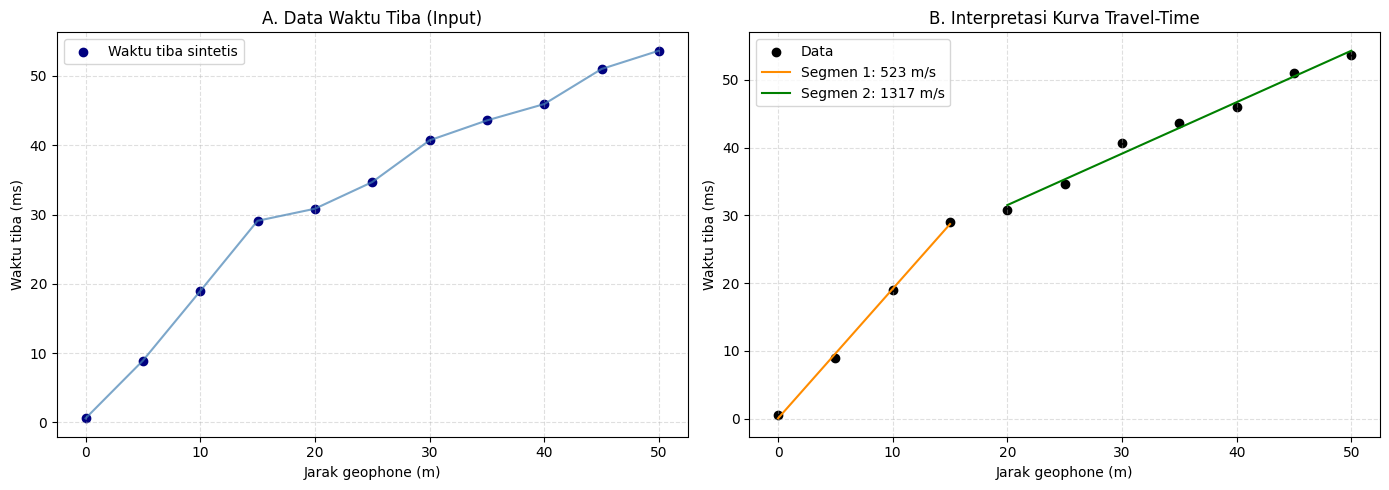

HASIL INTERPRETASI SEISMIK REFRAKSI (5 POIN OUTPUT)

1. POLA WAKTU TIBA:
   - Waktu tiba meningkat seiring bertambahnya jarak sumber-geophone.
2. ESTIMASI KECEPATAN:
   - Kecepatan semu segmen 1 sekitar 523 m/s.
   - Kecepatan semu segmen 2 sekitar 1317 m/s.
3. KEMUNGKINAN BATAS LAPISAN:
   - Perubahan kemiringan kurva menunjukkan kemungkinan perubahan kecepatan bawah permukaan.
4. INDIKASI BATUAN DASAR:
   - Segmen berkecepatan lebih tinggi dapat berkaitan dengan material lebih kompak, tetapi perlu bukti geologi.
5. KETERBATASAN:
   - Kedalaman antarmuka tidak dihitung karena model lapisan dan data waktu tiba lengkap belum tersedia.



In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA SINTETIS SEISMIK REFRAKSI
# ==============================================================================
np.random.seed(42)
x = np.arange(0, 51, 5, dtype=float)  # jarak geophone (m)
# Model waktu tiba sintetis: gelombang langsung lalu refraksi kepala
t_ms = np.where(x <= 15, x / 550 * 1000, 15 / 550 * 1000 + (x - 15) / 1300 * 1000)
t_ms += np.random.normal(0, 1.2, len(x))
t_ms = np.maximum(t_ms, 0)

# Regresi dua segmen untuk estimasi kecepatan semu
m1, b1 = np.polyfit(x[:4], t_ms[:4] / 1000, 1)
m2, b2 = np.polyfit(x[4:], t_ms[4:] / 1000, 1)
v1, v2 = 1 / m1, 1 / m2

# ==============================================================================
# 2. VISUALISASI DATA DAN HASIL INTERPRETASI
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(x, t_ms, color="navy", label="Waktu tiba sintetis")
ax1.plot(x, t_ms, color="steelblue", alpha=0.7)
ax1.set(title="A. Data Waktu Tiba (Input)", xlabel="Jarak geophone (m)", ylabel="Waktu tiba (ms)")
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend()

ax2.scatter(x, t_ms, color="black", label="Data")
ax2.plot(x[:4], (m1*x[:4] + b1)*1000, color="darkorange", label=f"Segmen 1: {v1:.0f} m/s")
ax2.plot(x[4:], (m2*x[4:] + b2)*1000, color="green", label=f"Segmen 2: {v2:.0f} m/s")
ax2.set(title="B. Interpretasi Kurva Travel-Time", xlabel="Jarak geophone (m)", ylabel="Waktu tiba (ms)")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend()
plt.tight_layout()
plt.show()

print(f"""HASIL INTERPRETASI SEISMIK REFRAKSI (5 POIN OUTPUT)

1. POLA WAKTU TIBA:
   - Waktu tiba meningkat seiring bertambahnya jarak sumber-geophone.
2. ESTIMASI KECEPATAN:
   - Kecepatan semu segmen 1 sekitar {v1:.0f} m/s.
   - Kecepatan semu segmen 2 sekitar {v2:.0f} m/s.
3. KEMUNGKINAN BATAS LAPISAN:
   - Perubahan kemiringan kurva menunjukkan kemungkinan perubahan kecepatan bawah permukaan.
4. INDIKASI BATUAN DASAR:
   - Segmen berkecepatan lebih tinggi dapat berkaitan dengan material lebih kompak, tetapi perlu bukti geologi.
5. KETERBATASAN:
   - Kedalaman antarmuka tidak dihitung karena model lapisan dan data waktu tiba lengkap belum tersedia.
""")

# **2. INTERPRETASI ANOMALI MAGNETIK UNTUK PEMETAAN STRUKTUR GEOLOGI**

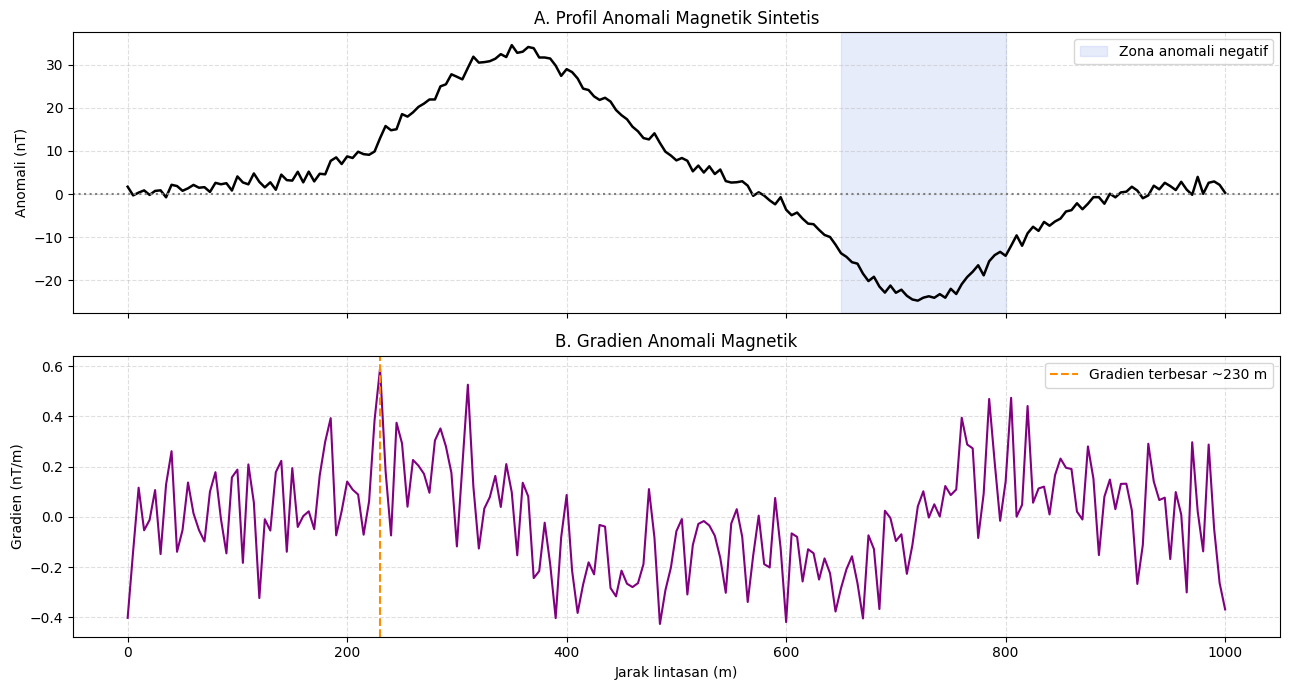

HASIL INTERPRETASI ANOMALI MAGNETIK (5 POIN OUTPUT)

1. POLA ANOMALI:
   - Anomali memperlihatkan zona positif dan negatif sepanjang lintasan.
2. ANOMALI TINGGI DAN RENDAH:
   - Nilai maksimum 34.58 nT dan minimum -24.76 nT.
3. ZONA PERUBAHAN TAJAM:
   - Gradien absolut terbesar berada sekitar jarak 230 m.
4. KEMUNGKINAN STRUKTUR GEOLOGI:
   - Perubahan gradien dapat menjadi petunjuk batas litologi atau struktur, tetapi bukan bukti tunggal sesar.
5. KETERBATASAN:
   - Interpretasi perlu dikombinasikan dengan koreksi data, peta geologi, dan transformasi magnetik bila tersedia.



In [2]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA ANOMALI MAGNETIK SINTETIS
# ==============================================================================
np.random.seed(7)
x = np.linspace(0, 1000, 201)
mag = 35*np.exp(-((x-350)/120)**2) - 22*np.exp(-((x-720)/100)**2)
mag += 2*np.sin(x/70) + np.random.normal(0, 1.0, len(x))
gradient = np.gradient(mag, x)
idx = np.argmax(np.abs(gradient))

# ==============================================================================
# 2. VISUALISASI PROFIL ANOMALI DAN GRADIEN
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax1.plot(x, mag, color="black", linewidth=1.8)
ax1.axhline(0, color="gray", linestyle=":")
ax1.axvspan(650, 800, color="royalblue", alpha=0.12, label="Zona anomali negatif")
ax1.set(title="A. Profil Anomali Magnetik Sintetis", ylabel="Anomali (nT)")
ax1.grid(True, linestyle="--", alpha=0.4); ax1.legend()
ax2.plot(x, gradient, color="purple")
ax2.axvline(x[idx], color="darkorange", linestyle="--", label=f"Gradien terbesar ~{x[idx]:.0f} m")
ax2.set(title="B. Gradien Anomali Magnetik", xlabel="Jarak lintasan (m)", ylabel="Gradien (nT/m)")
ax2.grid(True, linestyle="--", alpha=0.4); ax2.legend()
plt.tight_layout(); plt.show()

print(f"""HASIL INTERPRETASI ANOMALI MAGNETIK (5 POIN OUTPUT)

1. POLA ANOMALI:
   - Anomali memperlihatkan zona positif dan negatif sepanjang lintasan.
2. ANOMALI TINGGI DAN RENDAH:
   - Nilai maksimum {mag.max():.2f} nT dan minimum {mag.min():.2f} nT.
3. ZONA PERUBAHAN TAJAM:
   - Gradien absolut terbesar berada sekitar jarak {x[idx]:.0f} m.
4. KEMUNGKINAN STRUKTUR GEOLOGI:
   - Perubahan gradien dapat menjadi petunjuk batas litologi atau struktur, tetapi bukan bukti tunggal sesar.
5. KETERBATASAN:
   - Interpretasi perlu dikombinasikan dengan koreksi data, peta geologi, dan transformasi magnetik bila tersedia.
""")

# **3. INTERPRETASI ANOMALI GRAVITASI UNTUK STRUKTUR BAWAH PERMUKAAN**

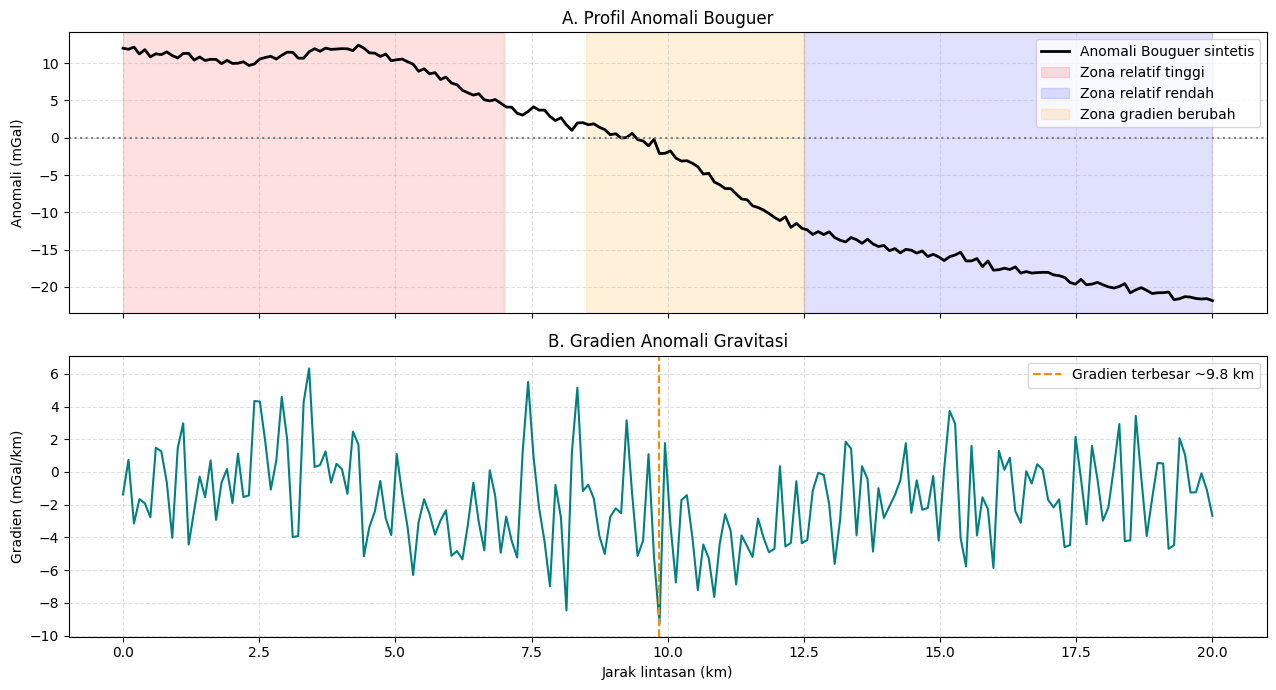

HASIL INTERPRETASI ANOMALI GRAVITASI (5 POIN OUTPUT)

1. POLA ANOMALI:
   - Profil memperlihatkan kecenderungan regional menurun dengan variasi lokal.
2. ZONA ANOMALI TINGGI DAN RENDAH:
   - Nilai maksimum 12.41 mGal dan minimum -21.84 mGal.
3. ZONA GRADIEN CURAM:
   - Gradien absolut terbesar berada sekitar 9.85 km.
4. KEMUNGKINAN STRUKTUR:
   - Perubahan gradien dapat mengindikasikan perubahan distribusi densitas atau batas struktur.
5. KETERBATASAN:
   - Sumber anomali gravitasi tidak unik; pemodelan dan informasi geologi diperlukan untuk menentukan kedalaman serta densitas.



In [3]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI DATA ANOMALI BOUGUER SINTETIS
# ==============================================================================
np.random.seed(21)
x = np.linspace(0, 20, 200)  # km
regional = 12 - 1.2*x
high = 5*np.exp(-((x-4.5)/1.8)**2)
low = -10/(1 + np.exp(-(x-11)/0.7))
gravity = regional + high + low + np.random.normal(0, 0.35, len(x))
grad = np.gradient(gravity, x)
idx = np.argmax(np.abs(grad))

# ==============================================================================
# 2. VISUALISASI ANOMALI, ZONA DAN GRADIEN
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax1.plot(x, gravity, color="black", linewidth=2, label="Anomali Bouguer sintetis")
ax1.axvspan(0, 7, color="red", alpha=0.12, label="Zona relatif tinggi")
ax1.axvspan(12.5, 20, color="blue", alpha=0.12, label="Zona relatif rendah")
ax1.axvspan(8.5, 12.5, color="orange", alpha=0.15, label="Zona gradien berubah")
ax1.axhline(0, color="gray", linestyle=":")
ax1.set(title="A. Profil Anomali Bouguer", ylabel="Anomali (mGal)")
ax1.grid(True, linestyle="--", alpha=0.4); ax1.legend()
ax2.plot(x, grad, color="teal")
ax2.axvline(x[idx], color="darkorange", linestyle="--", label=f"Gradien terbesar ~{x[idx]:.1f} km")
ax2.set(title="B. Gradien Anomali Gravitasi", xlabel="Jarak lintasan (km)", ylabel="Gradien (mGal/km)")
ax2.grid(True, linestyle="--", alpha=0.4); ax2.legend()
plt.tight_layout(); plt.show()

print(f"""HASIL INTERPRETASI ANOMALI GRAVITASI (5 POIN OUTPUT)

1. POLA ANOMALI:
   - Profil memperlihatkan kecenderungan regional menurun dengan variasi lokal.
2. ZONA ANOMALI TINGGI DAN RENDAH:
   - Nilai maksimum {gravity.max():.2f} mGal dan minimum {gravity.min():.2f} mGal.
3. ZONA GRADIEN CURAM:
   - Gradien absolut terbesar berada sekitar {x[idx]:.2f} km.
4. KEMUNGKINAN STRUKTUR:
   - Perubahan gradien dapat mengindikasikan perubahan distribusi densitas atau batas struktur.
5. KETERBATASAN:
   - Sumber anomali gravitasi tidak unik; pemodelan dan informasi geologi diperlukan untuk menentukan kedalaman serta densitas.
""")

# **4. ANALISIS GPR UNTUK IDENTIFIKASI STRUKTUR BAWAH PERMUKAAN DANGKAL**

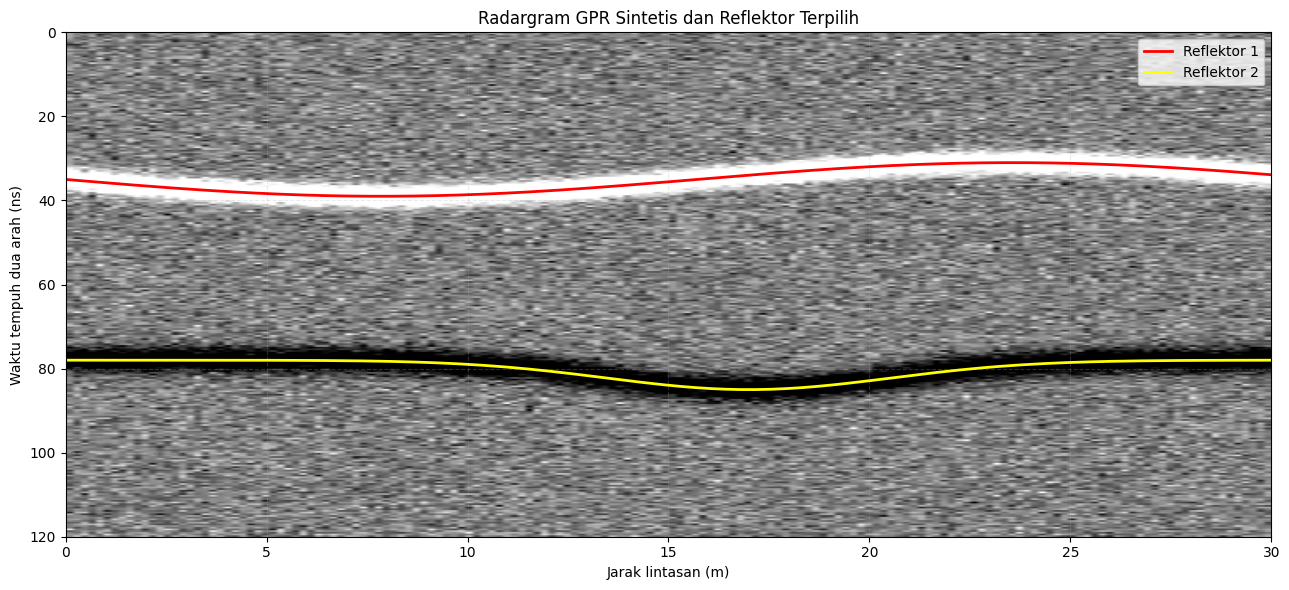

HASIL INTERPRETASI RADARGRAM GPR (5 POIN OUTPUT)

1. KARAKTERISTIK RADARGRAM:
   - Dua reflektor sintetis terlihat pada waktu tempuh yang berbeda.
2. KONTINUITAS REFLEKTOR:
   - Reflektor pertama relatif dangkal dan bergelombang; reflektor kedua lebih dalam dan melengkung.
3. ESTIMASI KEDALAMAN:
   - Dengan asumsi kecepatan 0.10 m/ns, reflektor 1 berada sekitar 1.75 m dan reflektor 2 sekitar 4.00 m.
4. KEMUNGKINAN KONTAK LAPISAN/OBJEK:
   - Perubahan bentuk reflektor dapat menjadi target interpretasi, tetapi bentuk radargram tidak cukup untuk memastikan jenis objek.
5. KETERBATASAN:
   - Kedalaman bergantung pada kecepatan gelombang dalam medium dan perlu dikalibrasi menggunakan data lapangan.



In [4]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & GENERASI RADARGRAM SINTETIS
# ==============================================================================
np.random.seed(10)
distance = np.linspace(0, 30, 160)
twt_ns = np.linspace(0, 120, 300)
X, T = np.meshgrid(distance, twt_ns)
radargram = np.random.normal(0, 0.12, X.shape)
reflector1 = 35 + 4*np.sin(distance/5)
reflector2 = 78 + 7*np.exp(-((distance-17)/5)**2)
for j in range(len(distance)):
    radargram[:, j] += 1.2*np.exp(-0.5*((twt_ns-reflector1[j])/1.6)**2)
    radargram[:, j] -= 0.8*np.exp(-0.5*((twt_ns-reflector2[j])/2.0)**2)

# Asumsi kecepatan EM untuk demonstrasi
v_em = 0.10  # m/ns
depth1 = v_em*reflector1/2
depth2 = v_em*reflector2/2

# ==============================================================================
# 2. VISUALISASI RADARGRAM DAN REFLEKTOR
# ==============================================================================
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(radargram, extent=[distance.min(), distance.max(), twt_ns.max(), twt_ns.min()],
               aspect="auto", cmap="gray", vmin=-0.45, vmax=0.45)
ax.plot(distance, reflector1, color="red", linewidth=2, label="Reflektor 1")
ax.plot(distance, reflector2, color="yellow", linewidth=2, label="Reflektor 2")
ax.set(title="Radargram GPR Sintetis dan Reflektor Terpilih",
       xlabel="Jarak lintasan (m)", ylabel="Waktu tempuh dua arah (ns)")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.25); plt.tight_layout(); plt.show()

print(f"""HASIL INTERPRETASI RADARGRAM GPR (5 POIN OUTPUT)

1. KARAKTERISTIK RADARGRAM:
   - Dua reflektor sintetis terlihat pada waktu tempuh yang berbeda.
2. KONTINUITAS REFLEKTOR:
   - Reflektor pertama relatif dangkal dan bergelombang; reflektor kedua lebih dalam dan melengkung.
3. ESTIMASI KEDALAMAN:
   - Dengan asumsi kecepatan {v_em:.2f} m/ns, reflektor 1 berada sekitar {depth1.mean():.2f} m dan reflektor 2 sekitar {depth2.mean():.2f} m.
4. KEMUNGKINAN KONTAK LAPISAN/OBJEK:
   - Perubahan bentuk reflektor dapat menjadi target interpretasi, tetapi bentuk radargram tidak cukup untuk memastikan jenis objek.
5. KETERBATASAN:
   - Kedalaman bergantung pada kecepatan gelombang dalam medium dan perlu dikalibrasi menggunakan data lapangan.
""")

# **5. ANALISIS MAGNETOTELURIK (MT) UNTUK IDENTIFIKASI SISTEM PANAS BUMI**

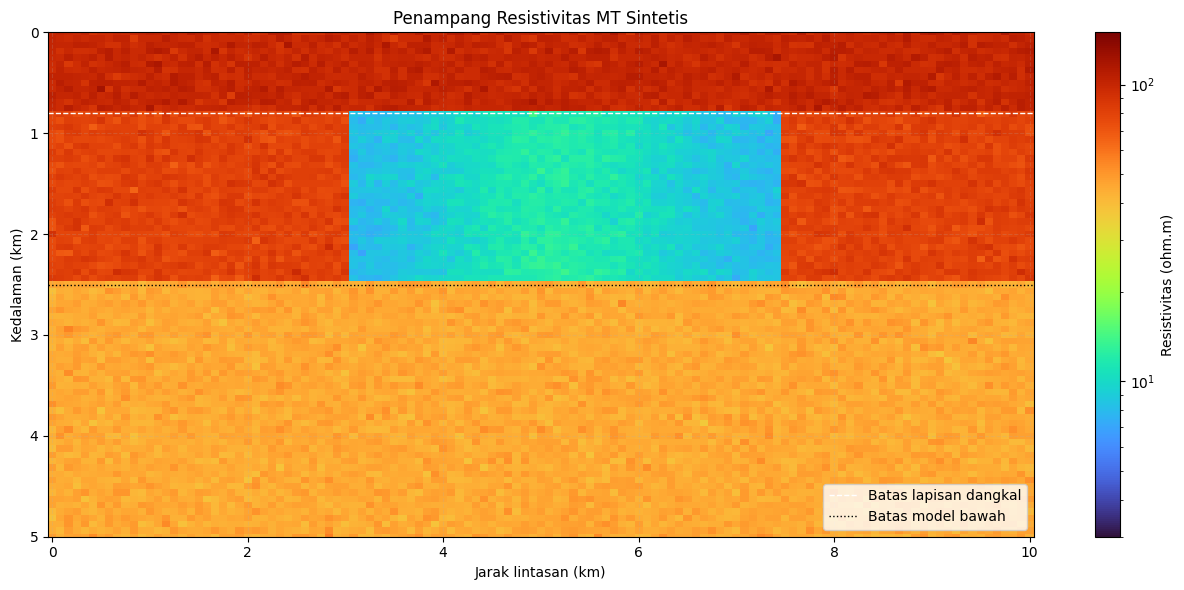

HASIL INTERPRETASI MODEL RESISTIVITAS MT (5 POIN OUTPUT)

1. DISTRIBUSI RESISTIVITAS:
   - Model menunjukkan lapisan dangkal resistif dan zona resistivitas rendah pada bagian tengah.
2. ZONA KONDUKTIF:
   - Resistivitas rendah sintetis berkisar sekitar 6.8–14.1 ohm.m.
3. KEMUNGKINAN SISTEM PANAS BUMI:
   - Zona konduktif dapat berkaitan dengan lempung alterasi atau fluida, tetapi tidak otomatis merupakan reservoir.
4. STRUKTUR BAWAH PERMUKAAN:
   - Geometri zona konduktif dapat membantu menyusun hipotesis model konseptual jika didukung data geologi dan manifestasi.
5. KETERBATASAN:
   - Model ini bukan hasil inversi MT; perlu data resistivitas semu, fase, frekuensi, dan evaluasi RMS untuk interpretasi lapangan.



In [5]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. SETUP & PEMODELAN RESISTIVITAS 2D SINTETIS
# ==============================================================================
np.random.seed(15)
x = np.linspace(0, 10, 121)       # posisi lintasan (km)
z = np.linspace(0, 5, 81)         # kedalaman (km)
X, Z = np.meshgrid(x, z)

# Model sederhana: lapisan dangkal resistif, zona konduktif tengah, dasar lebih resistif
rho = 80 + 0*X
rho[Z < 0.8] = 100
conductive = ((X > 3.0) & (X < 7.5) & (Z >= 0.8) & (Z < 2.5))
rho[conductive] = 8 + 4*np.exp(-((X[conductive]-5.2)/1.2)**2)
rho[Z >= 2.5] = 45
rho *= 10**np.random.normal(0, 0.025, rho.shape)
rho = np.clip(rho, 3, 150)

# ==============================================================================
# 2. VISUALISASI MODEL RESISTIVITAS
# ==============================================================================
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.pcolormesh(X, Z, rho, shading="auto", cmap="turbo", norm=plt.matplotlib.colors.LogNorm(vmin=3, vmax=150))
cb = plt.colorbar(im, ax=ax); cb.set_label("Resistivitas (ohm.m)")
ax.set_ylim(5, 0)
ax.set(title="Penampang Resistivitas MT Sintetis", xlabel="Jarak lintasan (km)", ylabel="Kedalaman (km)")
ax.axhline(0.8, color="white", linestyle="--", linewidth=1, label="Batas lapisan dangkal")
ax.axhline(2.5, color="black", linestyle=":", linewidth=1, label="Batas model bawah")
ax.legend(loc="lower right"); ax.grid(True, linestyle="--", alpha=0.2); plt.tight_layout(); plt.show()

print(f"""HASIL INTERPRETASI MODEL RESISTIVITAS MT (5 POIN OUTPUT)

1. DISTRIBUSI RESISTIVITAS:
   - Model menunjukkan lapisan dangkal resistif dan zona resistivitas rendah pada bagian tengah.
2. ZONA KONDUKTIF:
   - Resistivitas rendah sintetis berkisar sekitar {rho[conductive].min():.1f}–{rho[conductive].max():.1f} ohm.m.
3. KEMUNGKINAN SISTEM PANAS BUMI:
   - Zona konduktif dapat berkaitan dengan lempung alterasi atau fluida, tetapi tidak otomatis merupakan reservoir.
4. STRUKTUR BAWAH PERMUKAAN:
   - Geometri zona konduktif dapat membantu menyusun hipotesis model konseptual jika didukung data geologi dan manifestasi.
5. KETERBATASAN:
   - Model ini bukan hasil inversi MT; perlu data resistivitas semu, fase, frekuensi, dan evaluasi RMS untuk interpretasi lapangan.
""")